# FRB CNN Classifier — Training Notebook

**Fallback from LSTM** — LSTM won't synthesize at 256 timesteps.

Uses the same v6 dataset `(256, 256)` reshaped to `(256, 256, 1)` for Conv2D.

Architecture based on the pooled CNN that already synthesized in <2 minutes on the VU9P.

**FPGA constraints:**
- Flatten dimension < 500
- < 50k parameters
- io_stream + Resource strategy

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import json
from datetime import datetime

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, optimizers
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_curve, auc, precision_recall_curve
)

print(f"TensorFlow: {tf.__version__}")
print(f"GPUs: {tf.config.list_physical_devices('GPU')}")

set_seed = 42
tf.random.set_seed(set_seed)
np.random.seed(set_seed)

TensorFlow: 2.20.0
GPUs: []


In [2]:
# ============================================================
# ALL CONFIGURATION IN ONE PLACE
# ============================================================
CONFIG = {
    # --- Data ---
    "data_path": "./augmented_dataset/lstm_dataset_v6.npz",
    
    # --- CNN Architecture ---
    # Each entry: (filters, kernel_size)
    # MaxPool2D(2,2) is applied after each conv layer
    "conv_layers": [
        (2, 3),     # 256→128
        (4, 3),     # 128→64
        (4, 3),     # 64→32
        (4, 3),     # 32→16
        (4, 3),     # 16→8
    ],
    "conv_activation": "relu",
    "pool_size": (2, 2),
    
    "dense_units": [32],       # Dense layers after flatten
    "dense_dropout": 0.3,
    "dense_activation": "relu",
    
    "output_classes": 1,       # 1 = binary sigmoid, 2 = softmax
    
    # --- Training ---
    "batch_size": 128,
    "epochs": 150,
    "learning_rate": 1e-3,
    "optimizer": "adam",
    "lr_schedule": "reduce_on_plateau",
    "lr_patience": 10,
    "lr_factor": 0.5,
    "early_stop_patience": 30,
    "class_weight": "auto",
    
    # --- Output ---
    "save_dir": "./models/",
    "experiment_name": "cnn_v1",
}

print("Configuration:")
for k, v in CONFIG.items():
    print(f"  {k}: {v}")

Configuration:
  data_path: ./augmented_dataset/lstm_dataset_v6.npz
  conv_layers: [(2, 3), (4, 3), (4, 3), (4, 3), (4, 3)]
  conv_activation: relu
  pool_size: (2, 2)
  dense_units: [32]
  dense_dropout: 0.3
  dense_activation: relu
  output_classes: 1
  batch_size: 128
  epochs: 150
  learning_rate: 0.001
  optimizer: adam
  lr_schedule: reduce_on_plateau
  lr_patience: 10
  lr_factor: 0.5
  early_stop_patience: 30
  class_weight: auto
  save_dir: ./models/
  experiment_name: cnn_v1


## 1. Load Data

In [3]:
data = np.load(CONFIG["data_path"])
X_train, y_train = data["X_train"], data["y_train"]
X_val, y_val = data["X_val"], data["y_val"]
X_test, y_test = data["X_test"], data["y_test"]

print(f"Loaded: {X_train.shape}")

# Reshape (batch, 256, 256) → (batch, 256, 256, 1) for Conv2D
X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]

input_shape = X_train.shape[1:]  # (256, 256, 1)

print(f"Reshaped for CNN: {X_train.shape}")
print(f"Input shape: {input_shape}")
print(f"Train: {X_train.shape[0]} ({np.mean(y_train):.1%} FRB)")
print(f"Val:   {X_val.shape[0]} ({np.mean(y_val):.1%} FRB)")
print(f"Test:  {X_test.shape[0]} ({np.mean(y_test):.1%} FRB)")

Loaded: (1436, 256, 256)
Reshaped for CNN: (1436, 256, 256, 1)
Input shape: (256, 256, 1)
Train: 1436 (50.0% FRB)
Val:   308 (50.0% FRB)
Test:  308 (50.0% FRB)


## 2. Build Model

Key: MaxPooling aggressively reduces spatial dimensions so the flatten is small.

In [4]:
def build_cnn(config, input_shape):
    model = keras.Sequential()
    model.add(layers.Input(shape=input_shape, name='input_data'))
    
    # Conv + Pool blocks
    for i, (filters, kernel) in enumerate(config["conv_layers"]):
        model.add(layers.Conv2D(
            filters, (kernel, kernel),
            activation=config["conv_activation"],
            padding='same',
            name=f'conv_{i}'
        ))
        model.add(layers.MaxPooling2D(
            pool_size=config["pool_size"],
            name=f'pool_{i}'
        ))
    
    # Flatten
    model.add(layers.Flatten(name='flatten'))
    
    # Dense head
    for j, units in enumerate(config["dense_units"]):
        model.add(layers.Dense(
            units, activation=config["dense_activation"],
            name=f'dense_{j}'
        ))
        if config["dense_dropout"] > 0:
            model.add(layers.Dropout(config["dense_dropout"], name=f'drop_{j}'))
    
    # Output
    if config["output_classes"] == 1:
        model.add(layers.Dense(1, activation='sigmoid', name='output'))
    else:
        model.add(layers.Dense(config["output_classes"], activation='softmax', name='output'))
    
    return model

model = build_cnn(CONFIG, input_shape)
model.summary()

# Check flatten dimension — compute from last pooling layer output
# After 5 pool layers: 256 / 2^5 = 8, so 8 x 8 x last_filters
n_pools = len(CONFIG["conv_layers"])
spatial = 256 // (2 ** n_pools)
last_filters = CONFIG["conv_layers"][-1][0]
flatten_dim = spatial * spatial * last_filters

print(f"\nFlatten dimension: {flatten_dim}")
print(f"  ({spatial} x {spatial} x {last_filters})")
if flatten_dim > 500:
    print(f"⚠️  Over 500 — add more pooling or reduce filters")
else:
    print(f"✅ Under 500 — synthesis-friendly")

total_params = model.count_params()
print(f"\nTotal parameters: {total_params:,}")
print(f"{'✅ Under 50k' if total_params < 50000 else '⚠️  Over 50k FPGA budget'}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_0 (Conv2D)                 │ (None, 256, 256, 2)    │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_0 (MaxPooling2D)           │ (None, 128, 128, 2)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 128, 128, 4)    │            76 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 64, 64, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 64, 64, 4)      │           148 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 32, 32, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 32, 32, 4)      │           148 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 16, 16, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_4 (Conv2D)                 │ (None, 16, 16, 4)      │           148 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_4 (MaxPooling2D)           │ (None, 8, 8, 4)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_0 (Dense)                 │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_0 (Dropout)                │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,797 (34.36 KB)

 Trainable params: 8,797 (34.36 KB)

 Non-trainable params: 0 (0.00 B)


Flatten dimension: 256
  (8 x 8 x 4)
✅ Under 500 — synthesis-friendly

Total parameters: 8,797
✅ Under 50k


## 3. Compile & Train

In [5]:
# Optimizer
opt_map = {
    "adam": optimizers.Adam(learning_rate=CONFIG["learning_rate"]),
    "adamw": optimizers.AdamW(learning_rate=CONFIG["learning_rate"]),
    "sgd": optimizers.SGD(learning_rate=CONFIG["learning_rate"], momentum=0.9),
}
optimizer = opt_map[CONFIG["optimizer"]]

loss = 'binary_crossentropy' if CONFIG["output_classes"] == 1 else 'sparse_categorical_crossentropy'

model.compile(
    optimizer=optimizer,
    loss=loss,
    metrics=['accuracy'],
)

# Class weights
if CONFIG["class_weight"] == "auto":
    n_pos = np.sum(y_train == 1)
    n_neg = np.sum(y_train == 0)
    class_weight = {0: len(y_train) / (2 * n_neg), 1: len(y_train) / (2 * n_pos)}
    print(f"Class weights: {class_weight}")
elif CONFIG["class_weight"] == "none":
    class_weight = None
else:
    class_weight = CONFIG["class_weight"]

# Callbacks
save_dir = os.path.join(CONFIG["save_dir"], CONFIG["experiment_name"])
os.makedirs(save_dir, exist_ok=True)

cb_list = [
    callbacks.EarlyStopping(
        monitor='val_loss', patience=CONFIG['early_stop_patience'],
        restore_best_weights=True, verbose=1
    ),
    callbacks.ModelCheckpoint(
        os.path.join(save_dir, 'best_model.keras'),
        monitor='val_loss', save_best_only=True, verbose=0
    ),
]

if CONFIG['lr_schedule'] == 'reduce_on_plateau':
    cb_list.append(callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=CONFIG['lr_factor'],
        patience=CONFIG['lr_patience'], min_lr=1e-6, verbose=1
    ))

print(f"Callbacks: {[type(cb).__name__ for cb in cb_list]}")

Class weights: {0: np.float64(1.0), 1: np.float64(1.0)}
Callbacks: ['EarlyStopping', 'ModelCheckpoint', 'ReduceLROnPlateau']


In [6]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=CONFIG['epochs'],
    batch_size=CONFIG['batch_size'],
    class_weight=class_weight,
    callbacks=cb_list,
    verbose=1,
)

Epoch 1/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - accuracy: 0.5111 - loss: 0.6938 - val_accuracy: 0.5130 - val_loss: 0.6917 - learning_rate: 0.0010
Epoch 2/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.5223 - loss: 0.6913 - val_accuracy: 0.5130 - val_loss: 0.6915 - learning_rate: 0.0010
Epoch 3/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.5348 - loss: 0.6899 - val_accuracy: 0.5130 - val_loss: 0.6910 - learning_rate: 0.0010
Epoch 4/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.5460 - loss: 0.6874 - val_accuracy: 0.5130 - val_loss: 0.6892 - learning_rate: 0.0010
Epoch 5/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.5369 - loss: 0.6863 - val_accuracy: 0.5130 - val_loss: 0.6874 - learning_rate: 0.0010
Epoch 6/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.5383 - loss: 0.6842 - val_accuracy: 0.5130 - val_loss: 0.6837 - learning_rate: 0.0010
Epoch 7/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.5599 - loss: 0.6774 - 

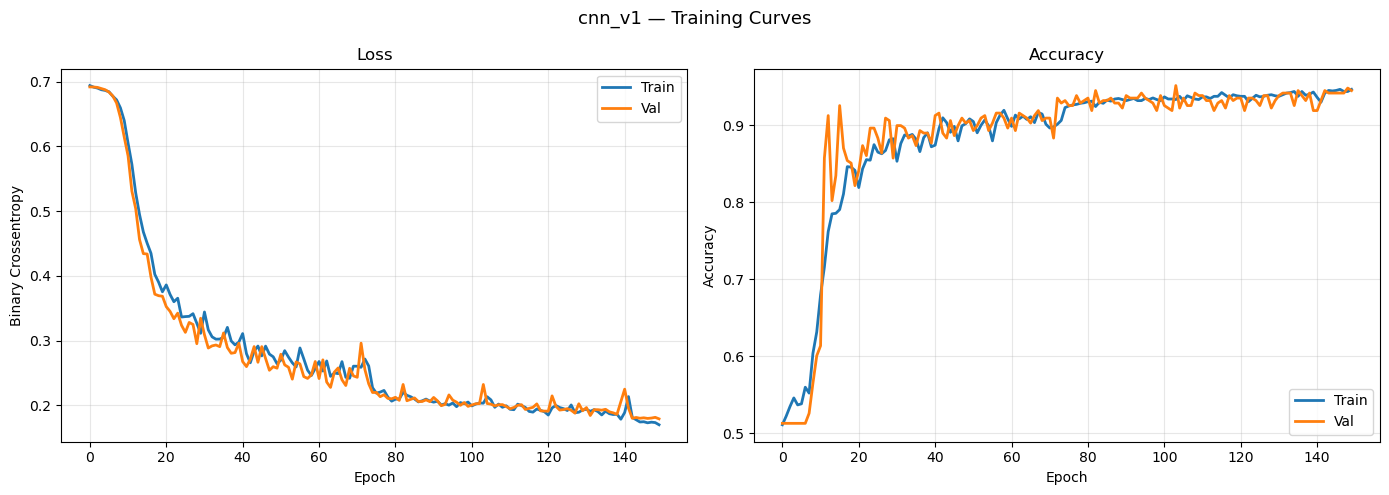

Best epoch: 150
  Val loss: 0.1792
  Val acc:  0.9448


In [7]:
# Training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['loss'], label='Train', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Val', linewidth=2)
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Binary Crossentropy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['accuracy'], label='Train', linewidth=2)
axes[1].plot(history.history['val_accuracy'], label='Val', linewidth=2)
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle(f"{CONFIG['experiment_name']} — Training Curves", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(save_dir, 'training_curves.png'), dpi=150)
plt.show()

best_epoch = np.argmin(history.history['val_loss'])
print(f"Best epoch: {best_epoch + 1}")
print(f"  Val loss: {history.history['val_loss'][best_epoch]:.4f}")
print(f"  Val acc:  {history.history['val_accuracy'][best_epoch]:.4f}")

## 4. Evaluate

In [8]:
y_pred_prob = model.predict(X_test, batch_size=CONFIG['batch_size']).flatten()
y_pred = (y_pred_prob >= 0.5).astype(int)

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"\n{classification_report(y_test, y_pred, target_names=['Noise', 'FRB'])}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Test Loss:     0.1278
Test Accuracy: 0.9740

              precision    recall  f1-score   support

       Noise       0.95      1.00      0.97       154
         FRB       1.00      0.95      0.97       154

    accuracy                           0.97       308
   macro avg       0.98      0.97      0.97       308
weighted avg       0.98      0.97      0.97       308



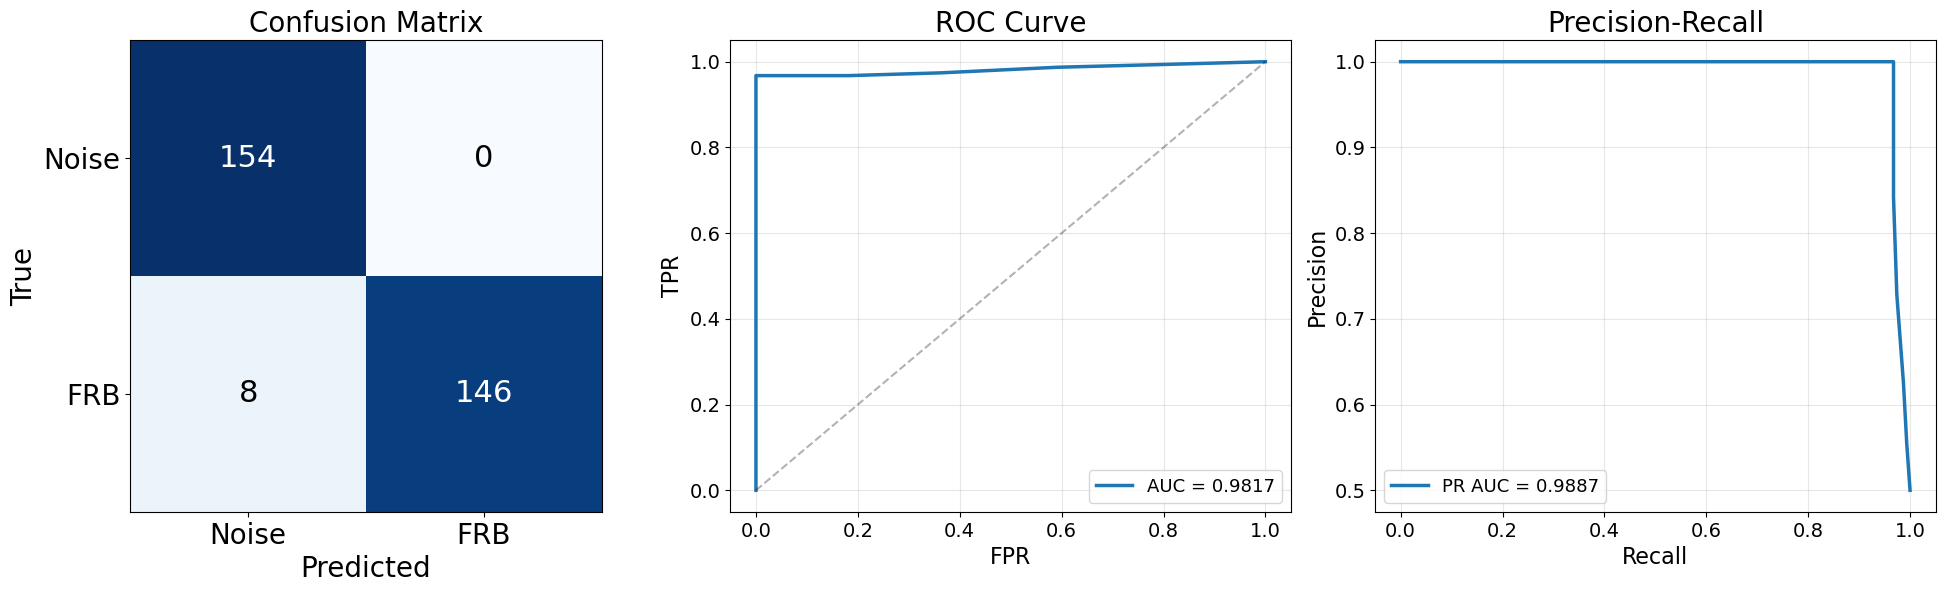

In [15]:
# Combined Test Evaluation: Confusion Matrix + ROC + Precision-Recall
# CM axis labels ("True"/"Predicted", "Noise"/"FRB") bumped to be close in
# size to the cell count numbers, per Ari's request.
TITLE_FS, SUPTITLE_FS, TICK_FS, ANNOT_FS, LEGEND_FS = 20, 24, 14, 22, 13
CM_LABEL_FS = 20
CM_TICKLABEL_FS = 20
ROC_PR_LABEL_FS = 16

os.makedirs('figures', exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
im = axes[0].imshow(cm, cmap='Blues')
axes[0].set_xticks([0, 1]); axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(['Noise', 'FRB'], fontsize=CM_TICKLABEL_FS)
axes[0].set_yticklabels(['Noise', 'FRB'], fontsize=CM_TICKLABEL_FS)
axes[0].set_xlabel('Predicted', fontsize=CM_LABEL_FS)
axes[0].set_ylabel('True', fontsize=CM_LABEL_FS)
axes[0].set_title('Confusion Matrix', fontsize=TITLE_FS)
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, f'{cm[i,j]}', ha='center', va='center', fontsize=ANNOT_FS,
                     color='white' if cm[i,j] > cm.max()/2 else 'black')

# ROC
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, linewidth=2.5, label=f'AUC = {roc_auc:.4f}')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.3)
axes[1].set_xlabel('FPR', fontsize=ROC_PR_LABEL_FS)
axes[1].set_ylabel('TPR', fontsize=ROC_PR_LABEL_FS)
axes[1].set_title('ROC Curve', fontsize=TITLE_FS)
axes[1].tick_params(labelsize=TICK_FS)
axes[1].legend(fontsize=LEGEND_FS)
axes[1].grid(True, alpha=0.3)

# Precision-Recall
precision, recall, _ = precision_recall_curve(y_test, y_pred_prob)
pr_auc = auc(recall, precision)
axes[2].plot(recall, precision, linewidth=2.5, label=f'PR AUC = {pr_auc:.4f}')
axes[2].set_xlabel('Recall', fontsize=ROC_PR_LABEL_FS)
axes[2].set_ylabel('Precision', fontsize=ROC_PR_LABEL_FS)
axes[2].set_title('Precision-Recall', fontsize=TITLE_FS)
axes[2].tick_params(labelsize=TICK_FS)
axes[2].legend(fontsize=LEGEND_FS)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/confusion_matrix.svg')
plt.show()

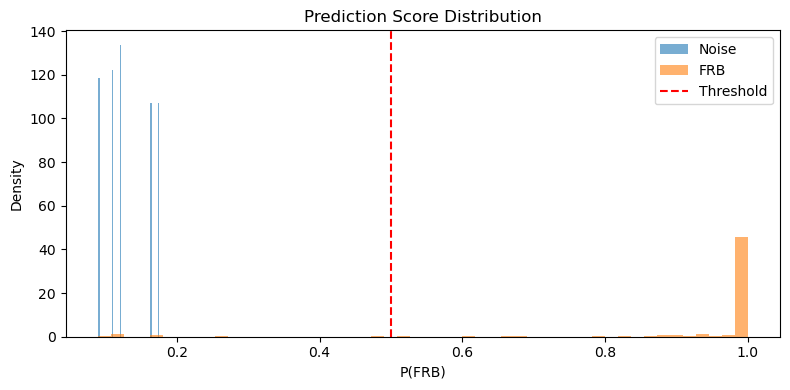


Recall vs Threshold:
  thresh=0.50  recall=0.948  precision=1.000  missed=8  false_alarms=0
  thresh=0.40  recall=0.955  precision=1.000  missed=7  false_alarms=0
  thresh=0.35  recall=0.955  precision=1.000  missed=7  false_alarms=0
  thresh=0.30  recall=0.955  precision=1.000  missed=7  false_alarms=0
  thresh=0.25  recall=0.961  precision=1.000  missed=6  false_alarms=0
  thresh=0.20  recall=0.961  precision=1.000  missed=6  false_alarms=0


In [10]:
# Prediction distribution
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y_pred_prob[y_test == 0], bins=50, alpha=0.6, label='Noise', density=True)
ax.hist(y_pred_prob[y_test == 1], bins=50, alpha=0.6, label='FRB', density=True)
ax.axvline(0.5, color='r', ls='--', label='Threshold')
ax.set_xlabel('P(FRB)'); ax.set_ylabel('Density')
ax.set_title('Prediction Score Distribution'); ax.legend()
plt.tight_layout()
plt.show()

# Recall at different thresholds
print("\nRecall vs Threshold:")
for thresh in [0.5, 0.4, 0.35, 0.3, 0.25, 0.2]:
    yp = (y_pred_prob >= thresh).astype(int)
    cm_t = confusion_matrix(y_test, yp)
    rec = cm_t[1,1] / (cm_t[1,0] + cm_t[1,1])
    prec = cm_t[1,1] / (cm_t[0,1] + cm_t[1,1]) if (cm_t[0,1] + cm_t[1,1]) > 0 else 0
    print(f"  thresh={thresh:.2f}  recall={rec:.3f}  precision={prec:.3f}  "
          f"missed={cm_t[1,0]}  false_alarms={cm_t[0,1]}")

## 5. Save

In [11]:
model.save(os.path.join(save_dir, 'model.keras'))
model.save(os.path.join(save_dir, 'model.h5'))

# Save config with results
config_save = CONFIG.copy()
config_save['total_params'] = int(model.count_params())
config_save['best_epoch'] = int(best_epoch + 1)
config_save['best_val_loss'] = float(history.history['val_loss'][best_epoch])
config_save['best_val_acc'] = float(history.history['val_accuracy'][best_epoch])
config_save['test_loss'] = float(test_loss)
config_save['test_acc'] = float(test_acc)
config_save['roc_auc'] = float(roc_auc)
config_save['pr_auc'] = float(pr_auc)
config_save['timestamp'] = datetime.now().isoformat()
config_save['input_shape'] = list(input_shape)

# Compute flatten dim
for layer in model.layers:
    n_pools = len(CONFIG["conv_layers"])
    spatial = 256 // (2 ** n_pools)
    last_filters = CONFIG["conv_layers"][-1][0]
    config_save['flatten_dim'] = spatial * spatial * last_filters

with open(os.path.join(save_dir, 'config.json'), 'w') as f:
    json.dump(config_save, f, indent=2)

hist_dict = {k: [float(v) for v in vals] for k, vals in history.history.items()}
with open(os.path.join(save_dir, 'history.json'), 'w') as f:
    json.dump(hist_dict, f, indent=2)

print(f"Saved to: {save_dir}/")
for fname in sorted(os.listdir(save_dir)):
    fsize = os.path.getsize(os.path.join(save_dir, fname))
    print(f"  {fname} ({fsize/1024:.1f} KB)")

Saved to: ./models/cnn_v1/
  best_model.keras (164.0 KB)
  config.json (1.1 KB)
  evaluation.png (81.0 KB)
  history.json (19.0 KB)
  model.h5 (166.1 KB)
  model.keras (164.0 KB)
  training_curves.png (125.4 KB)


In [12]:
print("=" * 60)
print("SUMMARY")
print("=" * 60)
print(f"Experiment:      {CONFIG['experiment_name']}")
print(f"Architecture:    {' → '.join(f'Conv2D({f},{k}x{k})+Pool' for f,k in CONFIG['conv_layers'])}")
print(f"                 → Flatten → {CONFIG['dense_units']} → sigmoid")
print(f"Parameters:      {model.count_params():,}")
print(f"Flatten dim:     {config_save.get('flatten_dim', 'N/A')}")
print(f"Input shape:     {input_shape}")
print(f"")
print(f"Test accuracy:   {test_acc:.4f}")
print(f"ROC AUC:         {roc_auc:.4f}")
print(f"PR AUC:          {pr_auc:.4f}")
print(f"")
print(f"FPGA ready:      flatten<500={'✅' if config_save.get('flatten_dim',9999)<500 else '❌'}, "
      f"params<50k={'✅' if model.count_params()<50000 else '❌'}")
print(f"")
print(f"Next: bring model.h5 to EC2 for hls4ml synthesis")
print(f"  Architecture for synthesis notebook:")
print(f"  Conv2D layers: {CONFIG['conv_layers']}")
print(f"  Dense: {CONFIG['dense_units']} + sigmoid output")
print(f"  Padding: same")

SUMMARY
Experiment:      cnn_v1
Architecture:    Conv2D(2,3x3)+Pool → Conv2D(4,3x3)+Pool → Conv2D(4,3x3)+Pool → Conv2D(4,3x3)+Pool → Conv2D(4,3x3)+Pool
                 → Flatten → [32] → sigmoid
Parameters:      8,797
Flatten dim:     256
Input shape:     (256, 256, 1)

Test accuracy:   0.9740
ROC AUC:         0.9817
PR AUC:          0.9887

FPGA ready:      flatten<500=✅, params<50k=✅

Next: bring model.h5 to EC2 for hls4ml synthesis
  Architecture for synthesis notebook:
  Conv2D layers: [(2, 3), (4, 3), (4, 3), (4, 3), (4, 3)]
  Dense: [32] + sigmoid output
  Padding: same


Measured 146 / 154 FRB patches

% of TRUE full-band sweep (real per-burst DM) used before trigger:
  Mean:   0.698%
  Median: 0.487%
  Min:    0.108%
  Max:    3.497%


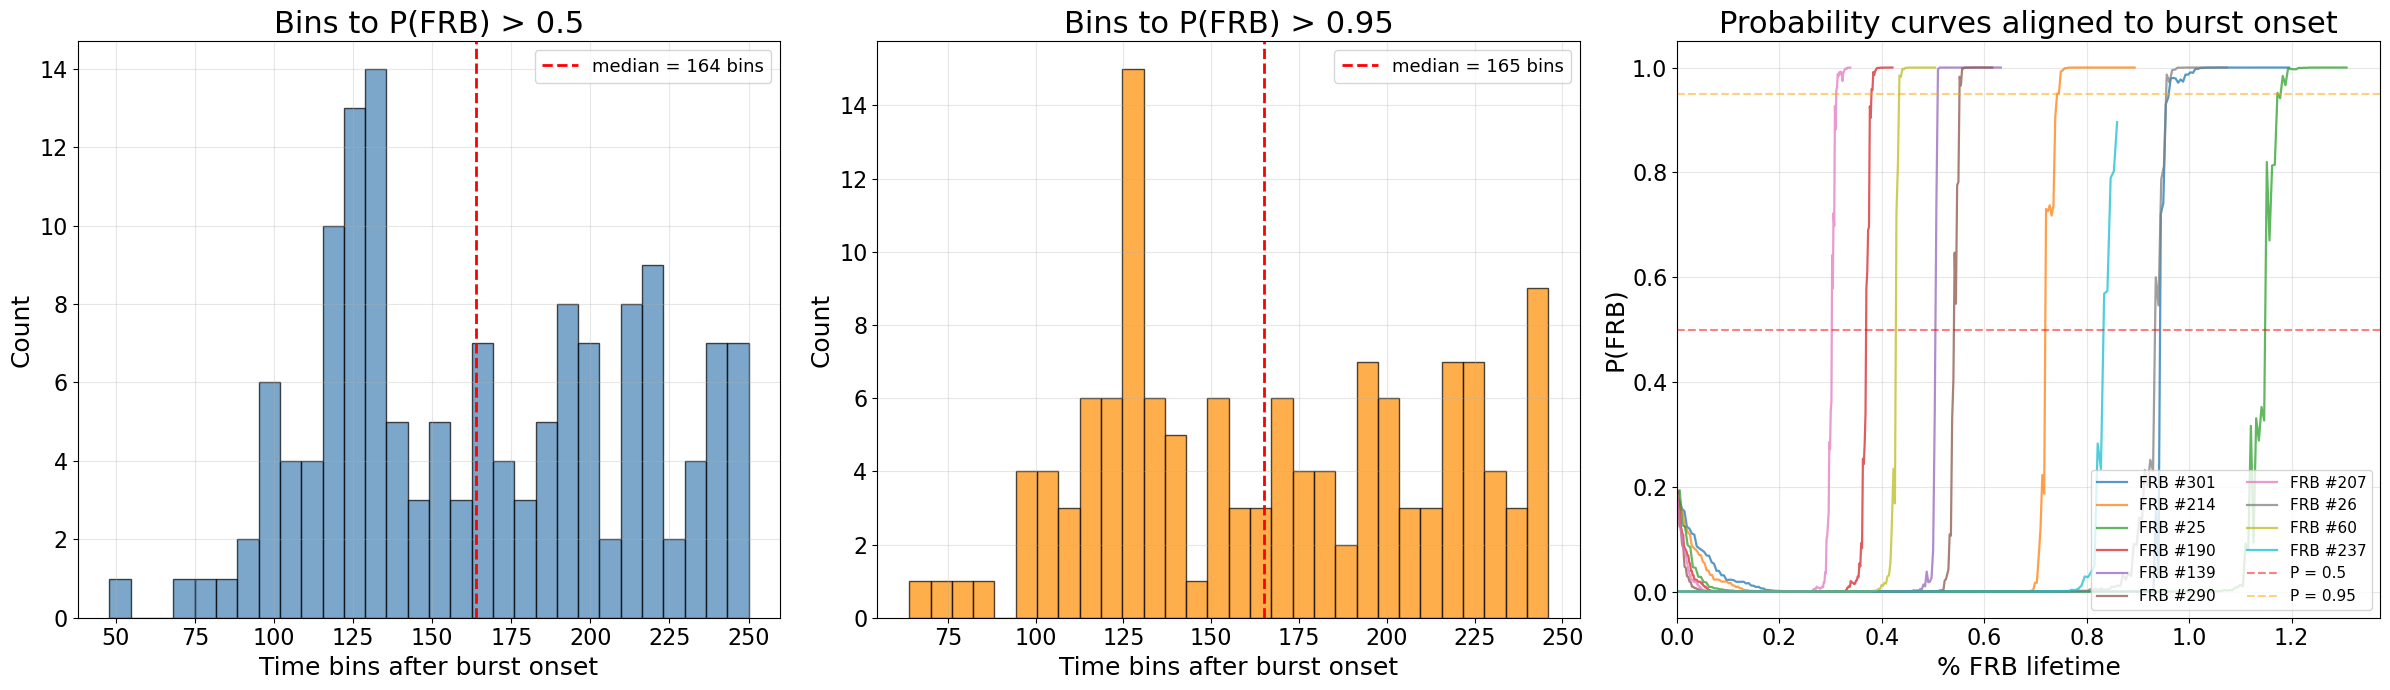

In [13]:
def find_burst_onset(patch, threshold_sigma=2.5, freq_frac=0.1):
    n_time, n_freq = patch.shape
    n_top = max(1, int(n_freq * freq_frac))
    top_band = patch[:, -n_top:]
    profile = np.mean(top_band, axis=1)

    med = np.median(profile)
    mad = np.median(np.abs(profile - med))
    sigma = mad * 1.4826
    if sigma < 1e-10:
        sigma = np.std(profile)
        if sigma < 1e-10:
            return None

    above = np.where(profile > med + threshold_sigma * sigma)[0]
    if len(above) == 0:
        return None
    return above[0]


def measure_detection_latency(model, patch, n_steps=256, fill_value=None,
                               trigger_thresh=0.5, converge_thresh=0.95):
    """Batched: all masked variants for this patch are built up front and
    scored in one model.predict() call instead of 256 individual calls."""
    n_time, n_freq = patch.shape
    step_size = max(1, n_time // n_steps)
    bins = np.arange(step_size, n_time + 1, step_size)

    batch = np.empty((len(bins), n_time, n_freq), dtype=patch.dtype)
    for i, t in enumerate(bins):
        masked = np.copy(patch)
        if fill_value is None:
            masked[t:, :] = masked[:t, :].mean()
        elif fill_value == 'noise':
            revealed = masked[:t, :]
            masked[t:, :] = np.random.normal(
                revealed.mean(), max(revealed.std(), 1e-6), masked[t:, :].shape
            )
        else:
            masked[t:, :] = fill_value
        batch[i] = masked

    probs = model.predict(batch[..., np.newaxis], verbose=0, batch_size=256).flatten()

    burst_onset = find_burst_onset(patch)
    trigger_bin = None
    converge_bin = None

    trigger_idxs = np.where(probs >= trigger_thresh)[0]
    if len(trigger_idxs) > 0:
        trigger_bin = bins[trigger_idxs[0]]

    converge_idxs = np.where(probs >= converge_thresh)[0]
    if len(converge_idxs) > 0:
        converge_bin = bins[converge_idxs[0]]

    return burst_onset, trigger_bin, converge_bin, bins, probs


# --- Physical constants (same as augmentation pipeline) ---
CHIME_FREQ_LOW = 400.0    # MHz
CHIME_FREQ_HIGH = 800.0   # MHz
K_DM = 4.148808e3
EFFECTIVE_TIME_RES = 2.56e-6 * 256  # seconds/bin (~0.655 ms)

def full_band_sweep_seconds(dm, freq_lo=CHIME_FREQ_LOW, freq_hi=CHIME_FREQ_HIGH):
    """True dispersion delay across the FULL observing band for this burst's
    actual DM -- same formula used to redisperse it during augmentation."""
    return K_DM * dm * (freq_lo**-2 - freq_hi**-2)

rng = np.random.default_rng(42)

# --- Load real per-example DM ---
# Requires frb_augmentation_v6_with_dm.ipynb to have been re-run on EC2 so
# lstm_dataset_v6.npz includes dm_train/dm_val/dm_test.
_data_with_dm = np.load(CONFIG["data_path"])
dm_test = _data_with_dm["dm_test"]  # NaN for noise, real DM (pc/cm3) for FRB examples

# --- Run on ALL FRB test examples ---
frb_test_idxs = np.where(y_test == 1)[0]

results = []
skipped_no_dm = 0
for idx in frb_test_idxs:
    dm = dm_test[idx]
    if np.isnan(dm):
        skipped_no_dm += 1
        continue

    patch = X_test[idx, :, :, 0]
    onset, trig, conv, bins, probs = measure_detection_latency(
        model, patch, n_steps=256, fill_value=None
    )
    if onset is None or trig is None:
        continue

    duration_sec = full_band_sweep_seconds(dm)  # TRUE full-band sweep, this burst's real DM

    results.append({
        'idx': idx,
        'dm': float(dm),
        'burst_onset': onset,
        'trigger_bin': trig,
        'converge_bin': conv,
        'bins_to_trigger': trig - onset,
        'bins_to_converge': conv - onset if conv is not None else None,
        'bins': bins,
        'probs': probs,
        'duration_sec': duration_sec,
    })

if skipped_no_dm:
    print(f"NOTE: {skipped_no_dm} FRB test examples had no DM recorded (unexpected) -- excluded.\n")

print(f"Measured {len(results)} / {len(frb_test_idxs)} FRB patches\n")

bins_to_trigger = np.array([r['bins_to_trigger'] for r in results])
bins_to_converge = np.array([r['bins_to_converge'] for r in results
                              if r['bins_to_converge'] is not None])

pct_of_true_sweep = np.array([
    100 * (r['bins_to_trigger'] * EFFECTIVE_TIME_RES) / r['duration_sec']
    for r in results
])
print("=" * 60)
print("% of TRUE full-band sweep (real per-burst DM) used before trigger:")
print(f"  Mean:   {pct_of_true_sweep.mean():.3f}%")
print(f"  Median: {np.median(pct_of_true_sweep):.3f}%")
print(f"  Min:    {pct_of_true_sweep.min():.3f}%")
print(f"  Max:    {pct_of_true_sweep.max():.3f}%")

# ============================================================
# Figure 1: 3-panel summary
# ============================================================
TITLE_FS, LABEL_FS, TICK_FS, LEGEND_FS = 22, 18, 16, 13
os.makedirs('figures', exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(24, 7))

ax = axes[0]
ax.hist(bins_to_trigger, bins=30, edgecolor='black', alpha=0.7, color='steelblue')
ax.axvline(np.median(bins_to_trigger), color='red', ls='--', lw=2,
           label=f'median = {np.median(bins_to_trigger):.0f} bins')
ax.set_xlabel('Time bins after burst onset', fontsize=LABEL_FS)
ax.set_ylabel('Count', fontsize=LABEL_FS)
ax.set_title('Bins to P(FRB) > 0.5', fontsize=TITLE_FS)
ax.tick_params(labelsize=TICK_FS)
ax.legend(fontsize=LEGEND_FS)
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.hist(bins_to_converge, bins=30, edgecolor='black', alpha=0.7, color='darkorange')
ax.axvline(np.median(bins_to_converge), color='red', ls='--', lw=2,
           label=f'median = {np.median(bins_to_converge):.0f} bins')
ax.set_xlabel('Time bins after burst onset', fontsize=LABEL_FS)
ax.set_ylabel('Count', fontsize=LABEL_FS)
ax.set_title('Bins to P(FRB) > 0.95', fontsize=TITLE_FS)
ax.tick_params(labelsize=TICK_FS)
ax.legend(fontsize=LEGEND_FS)
ax.grid(True, alpha=0.3)

ax = axes[2]
show_idxs = rng.choice(len(results), min(10, len(results)), replace=False)
for i in show_idxs:
    r = results[i]
    shifted_sec = (r['bins'] - r['burst_onset']) * EFFECTIVE_TIME_RES
    mask = shifted_sec >= 0
    pct_lifetime = shifted_sec[mask] / r['duration_sec'] * 100
    ax.plot(pct_lifetime, r['probs'][mask], alpha=0.75, linewidth=1.6,
            label=f"FRB #{r['idx']}")
ax.axhline(0.5, color='r', ls='--', alpha=0.5)
ax.axhline(0.95, color='orange', ls='--', alpha=0.5)
ax.text(0.98, 0.52, 'P = 0.5', transform=ax.get_yaxis_transform(),
        va='bottom', ha='right', color='r', fontsize=TICK_FS)
ax.text(0.98, 0.93, 'P = 0.95', transform=ax.get_yaxis_transform(),
        va='top', ha='right', color='orange', fontsize=TICK_FS)
ax.set_xlim(left=0)
ax.set_xlabel("% FRB lifetime", fontsize=LABEL_FS)
ax.set_ylabel('P(FRB)', fontsize=LABEL_FS)
ax.set_title('Probability curves aligned to burst onset', fontsize=TITLE_FS)
ax.tick_params(labelsize=TICK_FS)
ax.legend(fontsize=11, ncol=2, loc='lower right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/detection_latency.svg')
plt.show()

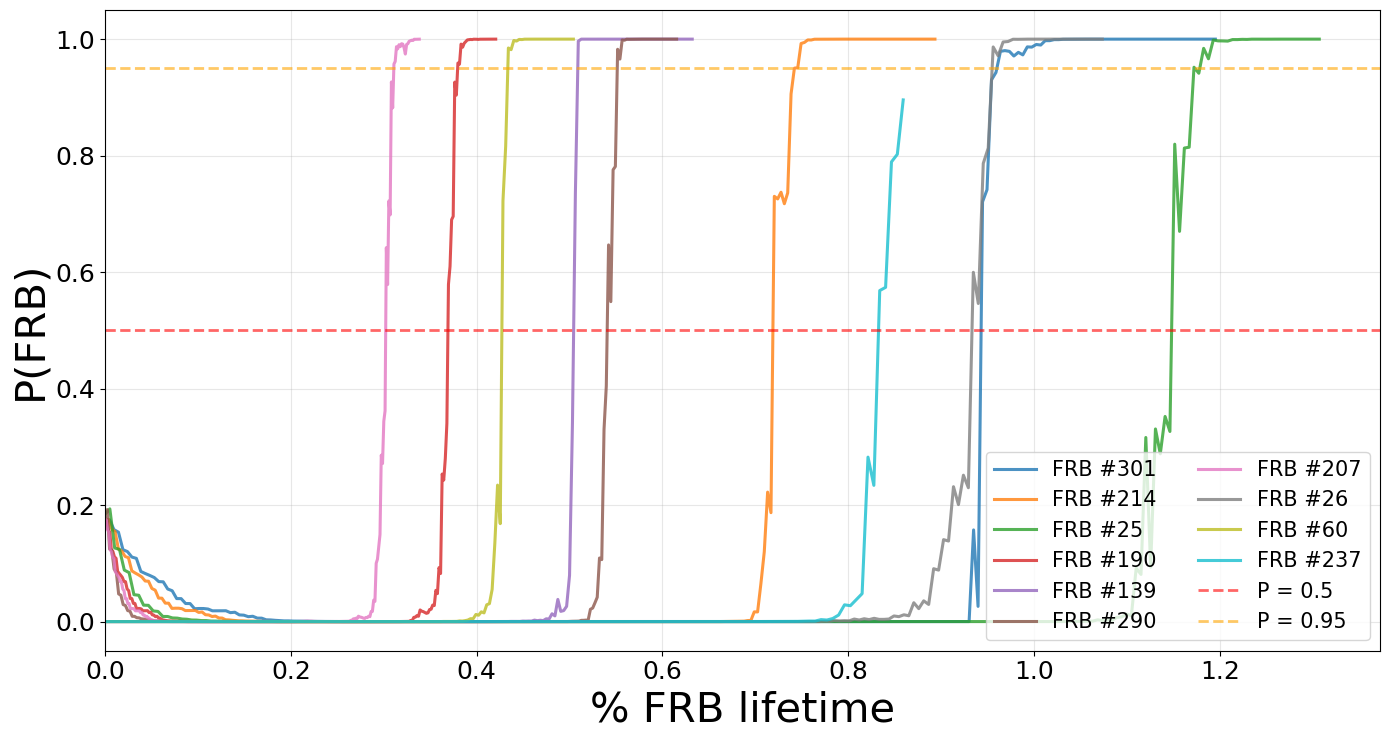

In [14]:
# Standalone probability-curves figure (Ari's requested edits):
#   - no title
#   - x-axis label: "% FRB lifetime"
#   - axis label font size up ~50% (20 -> 30)
#   - figure height down 25% (10 -> 7.5)
#   - legend: FRB # only, DM suppressed
STAND_LABEL_FS, STAND_TICK_FS, STAND_LEGEND_FS = 30, 22, 15

fig2, ax2 = plt.subplots(figsize=(14, 7.5))

for i in show_idxs:
    r = results[i]
    shifted_sec = (r['bins'] - r['burst_onset']) * EFFECTIVE_TIME_RES
    mask = shifted_sec >= 0
    pct_lifetime = shifted_sec[mask] / r['duration_sec'] * 100
    ax2.plot(pct_lifetime, r['probs'][mask], alpha=0.8, linewidth=2.2,
             label=f"FRB #{r['idx']}")

ax2.axhline(0.5, color='r', ls='--', linewidth=2, alpha=0.6)
ax2.axhline(0.95, color='orange', ls='--', linewidth=2, alpha=0.6)
ax2.text(0.98, 0.52, 'P = 0.5', transform=ax2.get_yaxis_transform(),
         va='bottom', ha='right', color='r', fontsize=STAND_TICK_FS)
ax2.text(0.98, 0.93, 'P = 0.95', transform=ax2.get_yaxis_transform(),
         va='top', ha='right', color='orange', fontsize=STAND_TICK_FS)
ax2.set_xlim(left=0)
ax2.set_xlabel('% FRB lifetime', fontsize=STAND_LABEL_FS)
ax2.set_ylabel('P(FRB)', fontsize=STAND_LABEL_FS)
ax2.tick_params(labelsize=STAND_TICK_FS)
ax2.legend(fontsize=STAND_LEGEND_FS, ncol=2, loc='lower right')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/probability_curves_standalone.svg')
plt.savefig('figures/probability_curves_standalone.png', dpi=200, bbox_inches='tight')
plt.show()